# Interpretation Analysis of the κ (kappa) operator

Same pipeline as `Analysis.ipynb`, but the Minimal Dyck Transformer (1 encoder layer, 1 decoder layer, 1 head, d_model = 128) is trained on
the operator κ from the *Dyck path – Nov 13th, 2026* notes (§5.2.3) instead of the zeta map:

$$\kappa(\varepsilon)=\varepsilon,\qquad \kappa(N\,x\,E\,y) = (NE\cdot x)\boxtimes y,$$

where $N x E y$ is the first-return decomposition and $\boxtimes$ is the zip product (interleave the bounce segments of the two paths).
Implementation: `src/utils/dyck_maps.py`. Inputs are identical to the zeta dataset (same Dyck words, same order, same train/eval split),
so example #15 here is the same input path as example #15 in `Analysis.ipynb`.

**Before running:**
1. `python dyck_data.py --n 13 --map kappa` &nbsp;→ `data/kappa_data_13.pkl` (pure Python, no SageMath)
2. `python train.py --config configs/kappa_config.yaml` &nbsp;→ `cache/sesh_*/` (here linked as `cache/n13_kappa_head1`)
3. Use the `.venv` kernel ("Python (DyckTransformer .venv)").

In [1]:
from matplotlib import pyplot as plt
from src.utils.config import load_config
import pickle
from src.data.dataset import Dataset, decode
from src.model.transformer import Transformer
from src.training.evaluator import Evaluator
from src.utils.transformer_analysis import *
from src.utils.dyck_maps import kappa, kappa_provenance, kappa_regions
from src.utils.kappa_analysis import provenance_alignment, plot_provenance_example, probe_regions, REGION_NAMES
# from src.data.dyck_generator import generate_dyck_data
import torch
import torch.nn as nn
import sys
import os
import numpy as np
import random
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Set random seeds:
seed = 42   # choose your random seed
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)  # For CUDA reproducibility
np.random.seed(seed)
random.seed(seed)
os.environ["PYTHONHASHSEED"] = str(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## 1. Load the model and dataset

In [2]:
#=================================
# load your model here by specifying the training session
#---------------------------------
sesh = 'n13_kappa_head1'  # kappa model: 1 head, n = 13 (symlink to the cache/sesh_* directory created by train.py)
                          # best_model.pth is updated during training, so this cell can be re-run while training continues

In [3]:
#=================================
# load config
config_path = f'cache/{sesh}/config'
config = load_config(config_path)

# load cached dataset, generate if not exists
batch_size = config['training']['batch_size']
n = config['data']['n']      
data_path = config['data']['data_path']
try:
    with open(data_path, 'rb') as f:
        data = pickle.load(f)
    print(f"Data loaded successfully from {data_path}.")
except FileNotFoundError:
    print(f"Data file not found.")
    # generate_dyck_data(n, data_path)
    with open(data_path, 'rb') as f:
        data = pickle.load(f)
    print(f"Data generated and loaded successfully.")
except Exception as e:
    raise Exception(f"Error loading saved data: {e}.")

# load the best trained model from the designated session
model_args = config['model']
if model_args['architecture'] == "decoder_only":
    model_args['max_len'] = (n*2+2)*2 # including BOS and EOS tokens from both input and target sequences
    max_new_tokens = 2*n + 2  # BOS, steps, EOS
else:
    model_args['max_len'] = n*2 + 1  # +1 for BOS token
    # max_new_tokens = model_args['max_len'] - 1  # Exclude BOS token, so -1
    max_new_tokens = n*2  # generate just the steps given BOS in the decoder

# load the datset
if model_args['architecture'] != "decoder_only":
    dataset = Dataset(data,seed=seed,batch_size=batch_size)
else:
    dataset = Dataset(data,seed=seed,batch_size=batch_size,decoder_only=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion = nn.CrossEntropyLoss()      
model = Transformer(**model_args)
model_path = f'cache/{sesh}/best_model.pth'
model.load_state_dict(torch.load(model_path,map_location=torch.device('cpu')))
model.to(device)
model.eval()
print(f"Best model loaded from {sesh}.")

# Evaluate the model on the validation dataset to see how it performs
evaluator = Evaluator(model, dataset.eval_dataloader, criterion, device)
eval_loss_epoch, eval_accuracy_epoch = evaluator.evaluate(max_new_tokens)
print(f"validation data: loss = {eval_loss_epoch:.4f}, accuracy = {eval_accuracy_epoch:.8f}")

# load analysis examples from the validation dataset
examples = {
    'inputs': dataset.eval_dataloader.dataset.tensors[0].to(device),  # First 5 inputs
    'targets': dataset.eval_dataloader.dataset.tensors[1].to(device)   # First 5 targets
}

# sanity check: the targets really are kappa(inputs)
_sym = lambda row: [int(t) - 2 for t in row[1:]]
assert all(kappa(_sym(x.tolist())) == _sym(y.tolist()) for x, y in zip(examples['inputs'][:2000], examples['targets'][:2000]))
print(f"Targets verified to equal kappa(inputs) on 2000 eval examples. Eval set size: {len(examples['inputs'])}")

Data loaded successfully from data/kappa_data_13.pkl.
Best model loaded from n13_kappa_head1.
validation data: loss = 0.0636, accuracy = 0.72940000
Targets verified to equal kappa(inputs) on 2000 eval examples. Eval set size: 10000


## 2. Example Usage

### Example 2a. Visualize encoder, decoder self-attention, cross-attention, and Dyck Paths for one example

Input: bos 1 1 1 0 1 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 0
Target: bos 1 0 1 1 0 1 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0


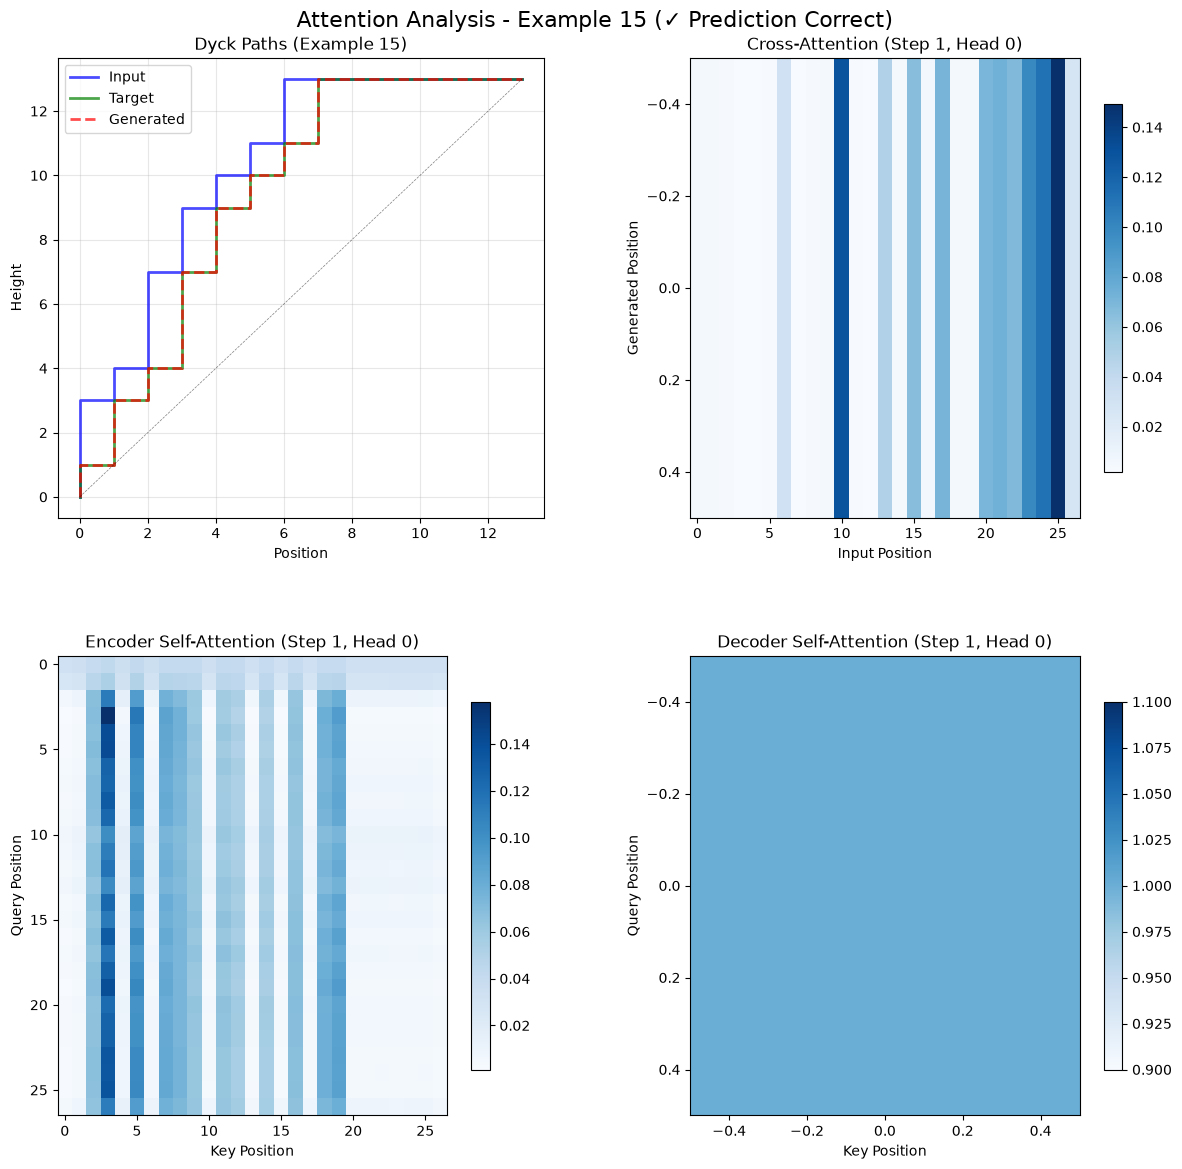

In [4]:
# Example: Analyze data example #15
# this if for all attention heads numbered 0 at step 21 (the 22th token generated in the sequence)
#=================
# choose the example, step of generation and attention heads to analyze
ex_idx = 15  # the index of the first example to analyze
encoder_att_head = 0  # which encoder self-attention head to analyze. 0 means the first head
decoder_att_head = 0  # which decoder self-attention head to analyze. 0 means the first head
cross_att_head = 0  # which cross-attention head to analyze. 0 means the first head
step =  0 # which token is being generated in the sequence when analyzing cross-attention. 0 means the first token after BOS.
# some plotting parameters
figsize = (12,12)  # figure size for visualization
cmap = 'Blues'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
# outputs = analyze_cross_attention(model, examples, start_idx=start_idx, step=step, att_head=att_head, num_examples=num_examples)
print(f"Input: {decode(examples['inputs'][ex_idx], dataset.dictionary)}")
print(f"Target: {decode(examples['targets'][ex_idx], dataset.dictionary)}")

outputs = attention_example(model, examples, dataset, ex_idx=ex_idx, step=step, encoder_att_head=encoder_att_head, decoder_att_head=decoder_att_head, cross_att_head=cross_att_head, figsize=figsize, cmap=cmap)

### Example 2b. Visualize Cross Attentions for a Batch of Examples

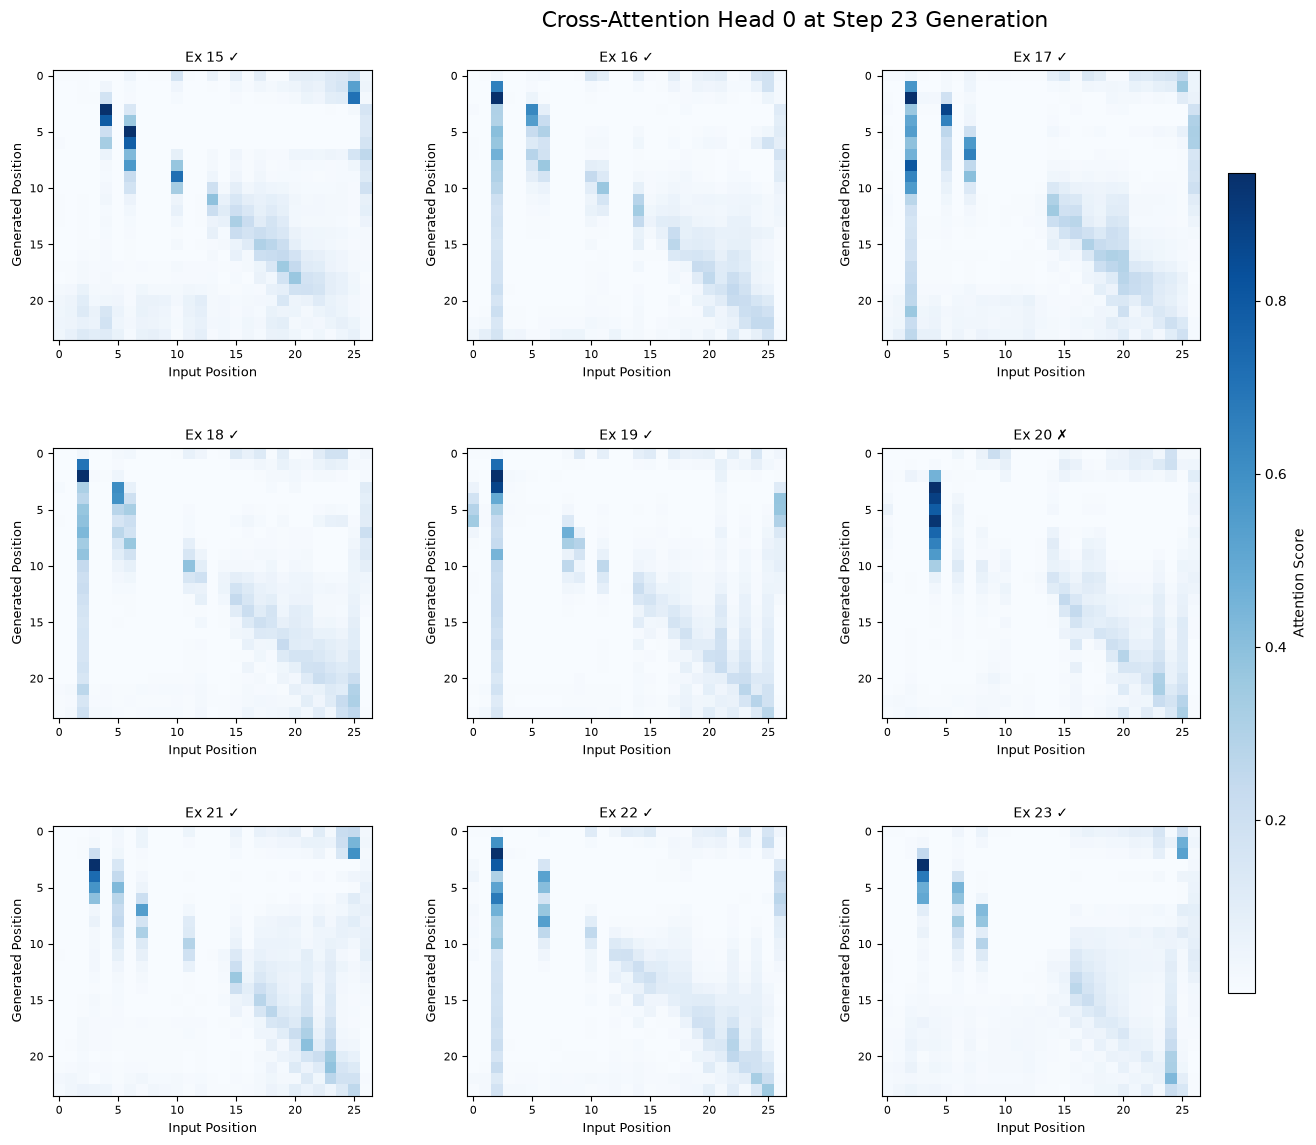

In [5]:
# Example: Analyze 9 examples starting from example #15
# all for attention head 0 at step 21 (the 22th token generated in the sequence)
# The ✓ and ✗ in the title indicate whether the Dyck path is predicted correctly or not
#=================
# choose the examples, step of generation and attention heads to analyze
start_idx = 15  # the index of the first example to analyze
num_examples = 9  # Number of examples to show
att_head = 0    # attention head to visualize
step = 23  # which token is being generated in the sequence when analyzing cross-attention. 0 means the first token after BOS.
# some plotting parameters
figsize = (16, 12)  # figure size for visualization
cmap = 'Blues'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
outputs = analyze_cross_attention(model, examples, start_idx=start_idx, step=step, att_head=att_head, num_examples=num_examples, figsize=figsize, cmap=cmap)

### Example 2c. Visualize encoder self attention for a batch of examples

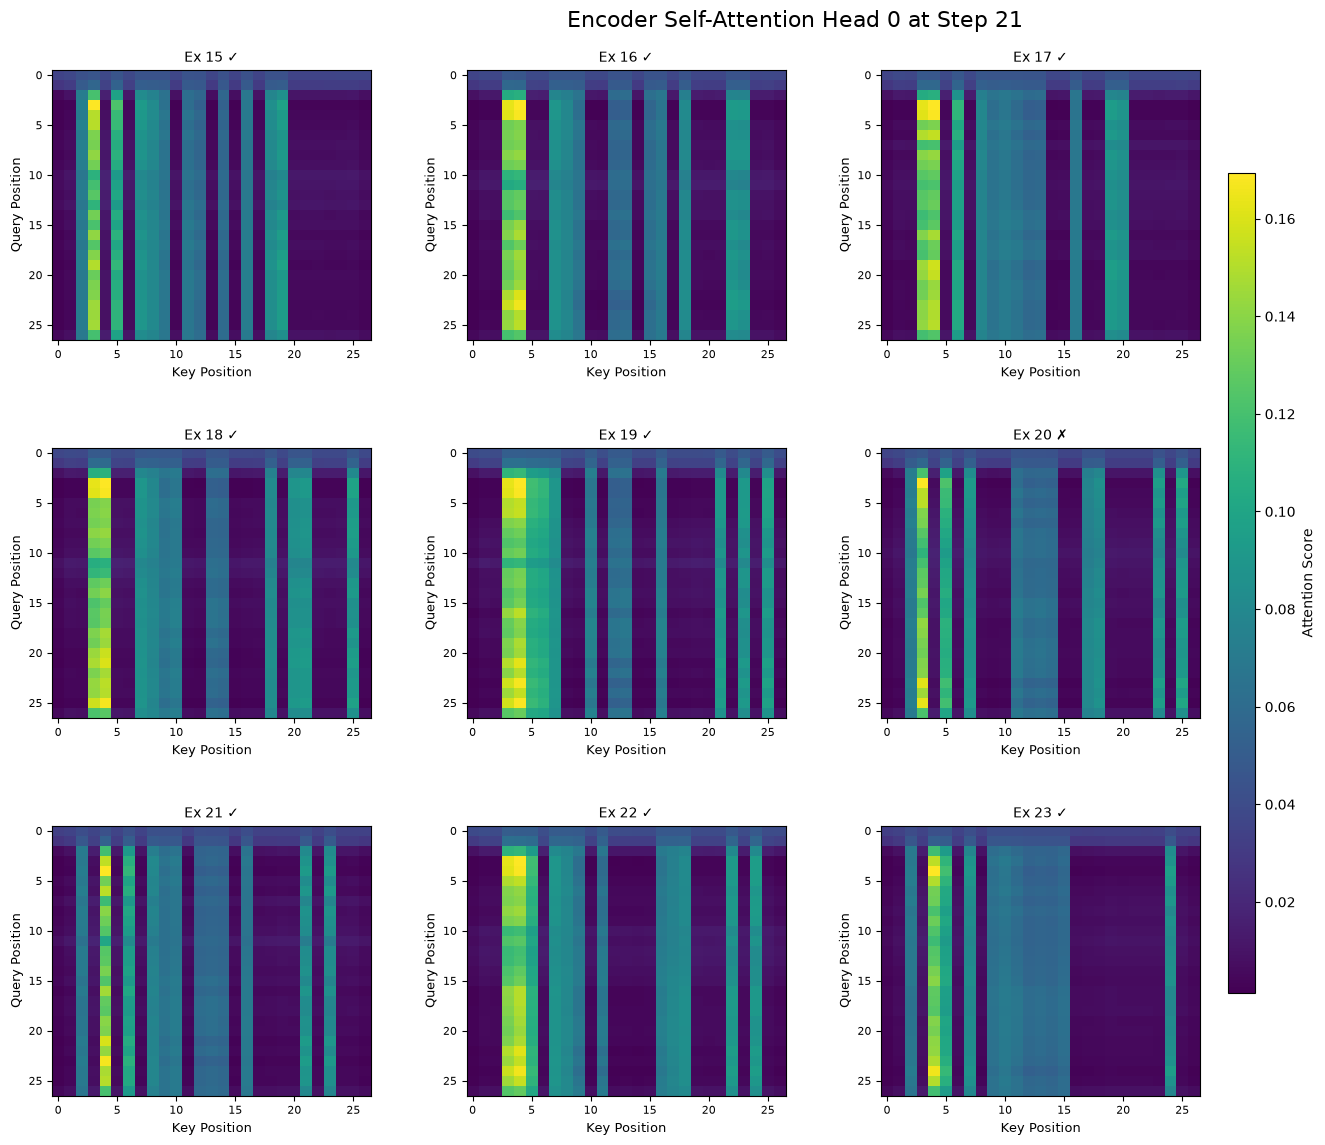

In [6]:
# Example: Analyze 9 examples starting from example #15
# all for attention head 0 at step 21 (the 22th token generated in the sequence)
# The ✓ and ✗ in the title indicate whether the Dyck path is predicted correctly or not
#=================
# choose the examples, step of generation and attention heads to analyze
start_idx = 15  # the index of the first example to analyze
num_examples = 9  # Number of examples to show
att_head = 0    # attention head to visualize
step = 21  # which token is being generated in the sequence when analyzing attention
# some plotting parameters
figsize = (16, 12)  # figure size for visualization
cmap = 'viridis'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
outputs = analyze_encoder_attention(model, examples, start_idx=start_idx, step=step, att_head=att_head, num_examples=num_examples, figsize=figsize, cmap=cmap)

### Example 2d. Visualize decoder self attention for a batch of examples

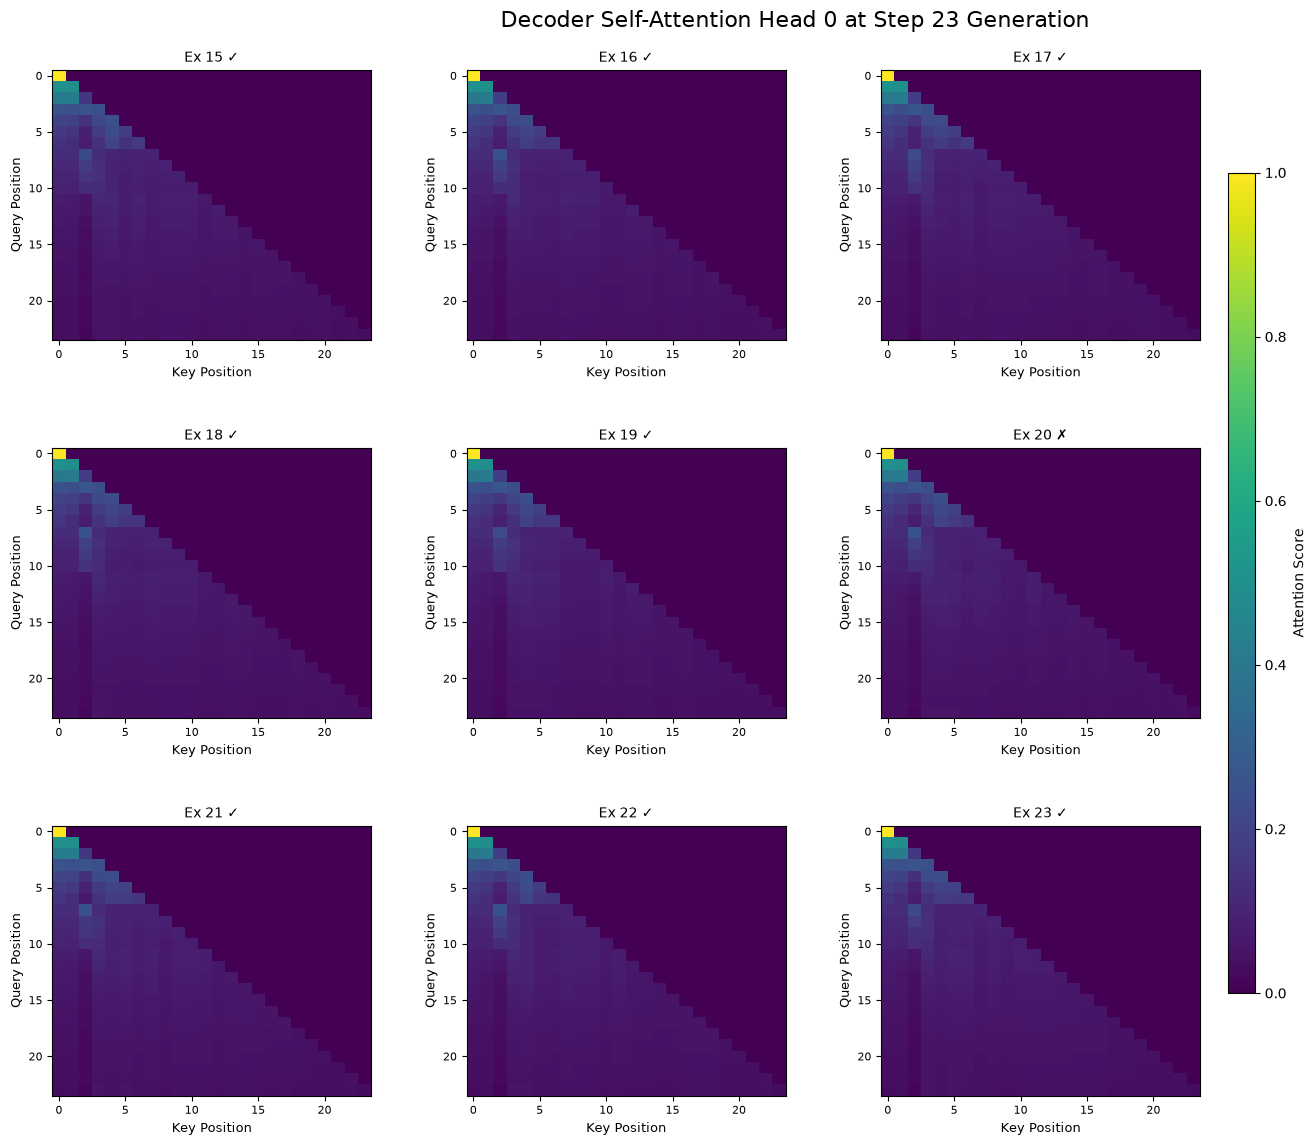

In [7]:
# Example: Analyze 9 examples starting from example #15
# all for attention head 0 at step 21 (the 22th token generated in the sequence)
# The ✓ and ✗ in the title indicate whether the Dyck path is predicted correctly or not
#=================
# choose the examples, step of generation and attention heads to analyze
start_idx = 15  # the index of the first example to analyze
num_examples = 9  # Number of examples to show
att_head = 0    # attention head to visualize
step = 23  # which token is being generated in the sequence when analyzing attention
# some plotting parameters
figsize = (16, 12)  # figure size for visualization
cmap = 'viridis'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
outputs = analyze_decoder_attention(model, examples, start_idx=start_idx, step=step, att_head=att_head, num_examples=num_examples, figsize=figsize, cmap=cmap)

### Example 2e. Visualize cross attention across all the steps

Input: bos 1 0 1 1 0 1 0 1 1 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 0
Target: bos 1 1 1 0 0 1 0 1 1 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 0


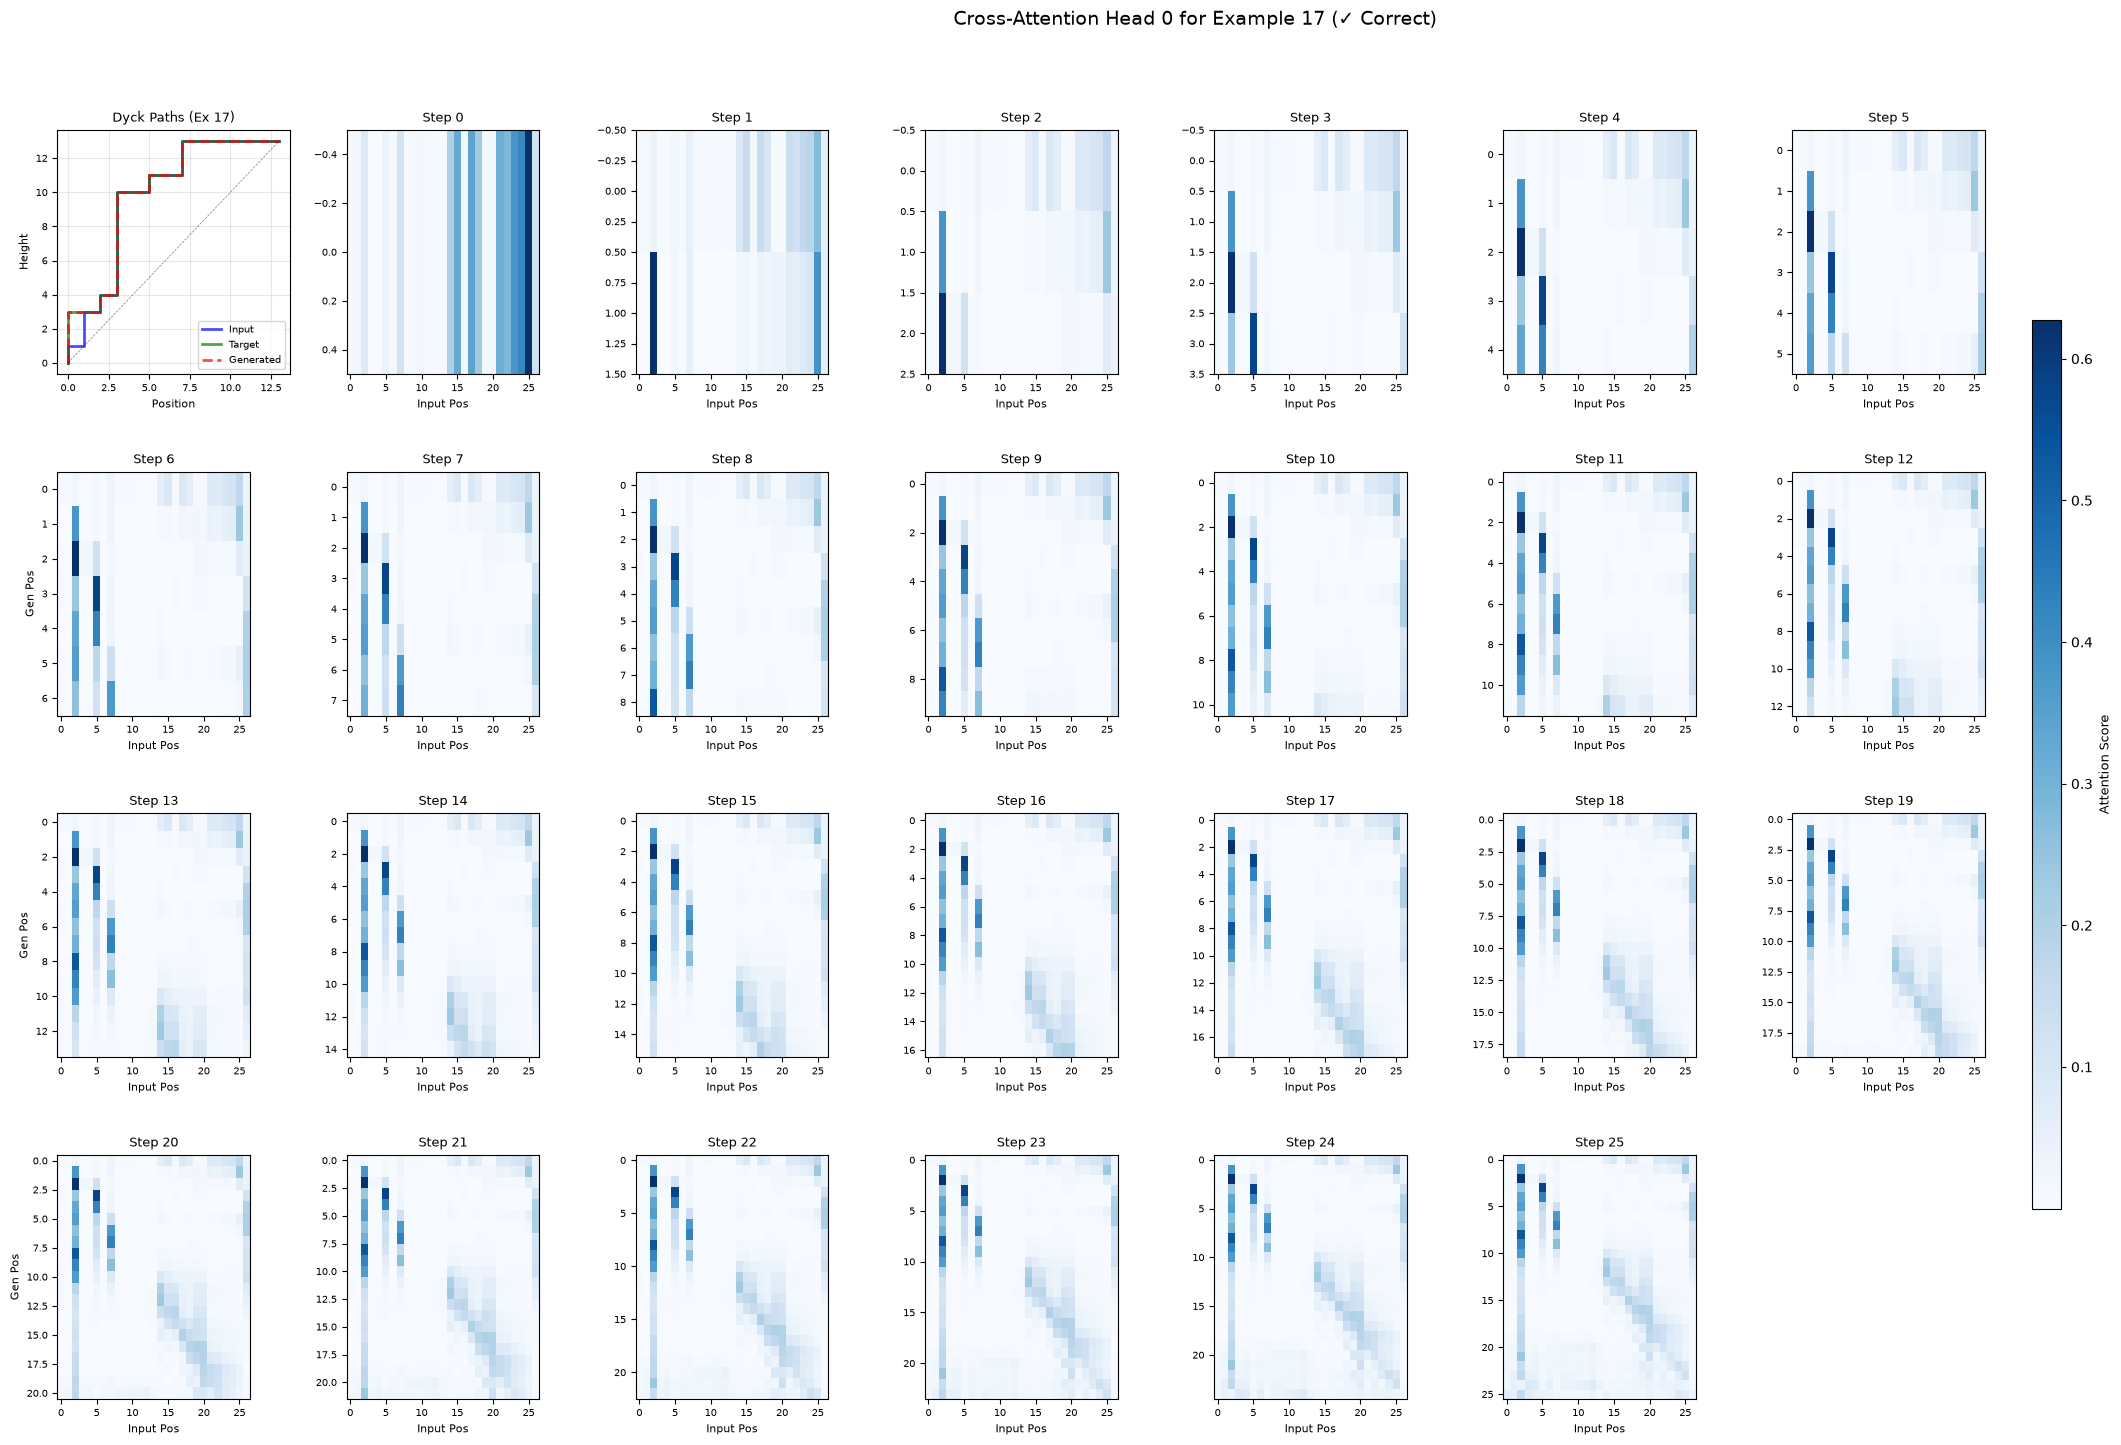

In [8]:
# Example: Analyze example #15
# this generates attention maps for all steps in one sequence generation
#=================
# choose the example and attention heads to analyze
ex_idx = 17 # the index of the first example to analyze
att_head = 0    # attention head to visualize
# some plotting parameters
figsize = (24,15)  # figure size for visualization
cmap = 'Blues'  # colormap for visualization, e.g. 'Blues', 'inferno', 'viridis'
#=================
print(f"Input: {decode(examples['inputs'][ex_idx], dataset.dictionary)}")
print(f"Target: {decode(examples['targets'][ex_idx], dataset.dictionary)}")

outputs = analyze_cross_attention_all_steps(model, examples, dataset, ex_idx=ex_idx, att_head=att_head, figsize=figsize, cmap=cmap)

### Example 2f. Level vs. Cross-Attention Comparison

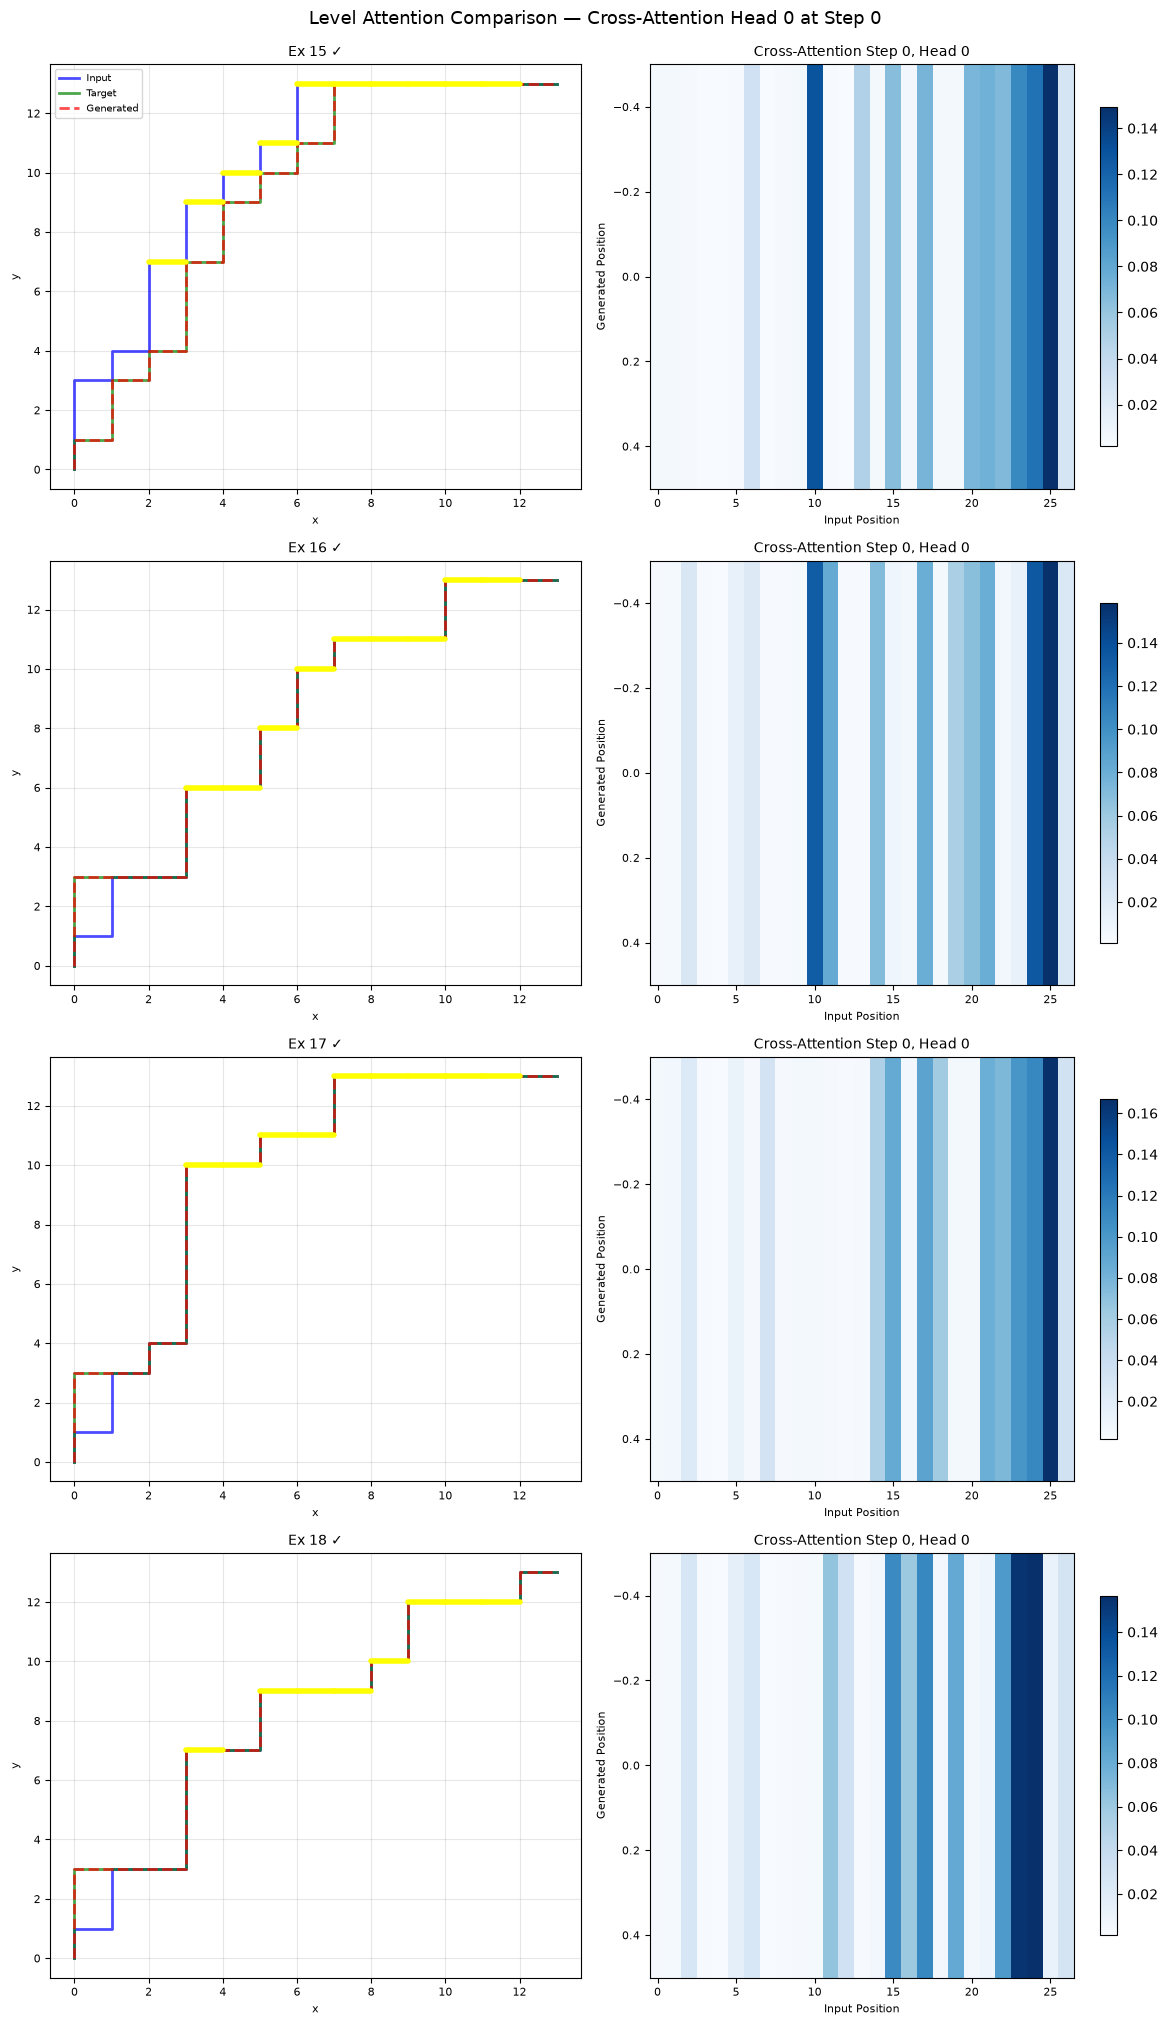

In [9]:
# For 4 consecutive examples, plot side-by-side:
#   Left  — Input / Target / Generated Dyck paths; yellow dots mark input positions
#            with above-mean cross-attention weight at step 0 (the first generated token)
#   Right — Cross-attention heatmap at step 0 (bimodal: near-zero vs. high weights)
#=================
start_idx = 15   # first of the 4 consecutive examples
att_head  = 0    # which cross-attention head to inspect
figsize   = (12, 20)
cmap      = 'Blues'
#=================
level_attention_comparison(
    model, examples, dataset,
    start_idx=start_idx,
    att_head=att_head,
    figsize=figsize,
    cmap=cmap
)

### Example 2g. PCA of encoder and decoder embeddings

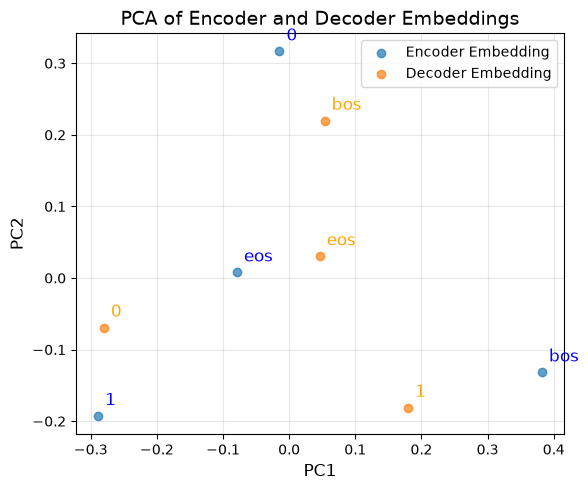

In [10]:
# run a PCA on the encoder and decoder token embeddings
# note: it is likely that the encoder and decoder used different pca projections
outputs = analyze_embeddings_pca(model, dataset, figsize=(6, 5), alpha=0.7, fontsize=12)

## Visualize positional Embeddings

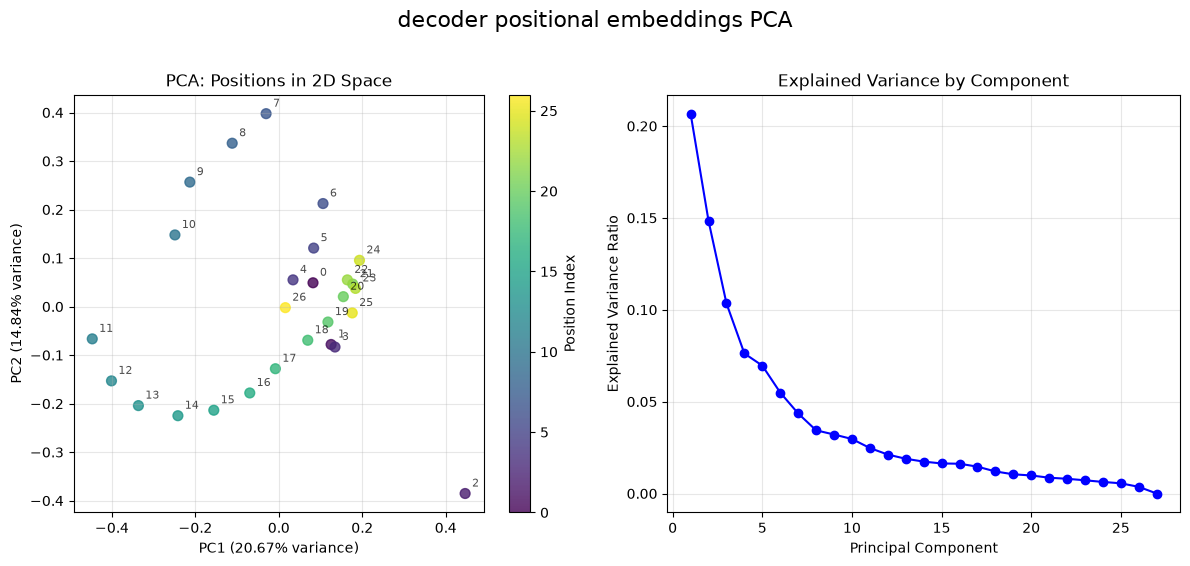

{'pos_pca_full': array([[ 8.19566548e-02,  4.91124876e-02,  2.84534357e-02,
         -5.50328195e-02, -3.69713120e-02, -6.35775030e-02,
          2.99929008e-02, -3.35433744e-02,  2.38568820e-02,
          2.40517184e-02,  5.12886271e-02, -6.88349679e-02,
          4.17526513e-02,  7.41086304e-02, -4.13614996e-02,
          2.35778913e-02, -1.12740733e-01, -3.74284424e-02,
          4.56538051e-02,  3.04427370e-03,  1.94877647e-02,
         -2.62785098e-03,  2.72743627e-02,  1.17720433e-01,
          5.09218909e-02, -2.49999743e-02, -1.63206177e-08],
        [ 1.25343636e-01, -7.80733004e-02,  1.36250138e-01,
         -4.59565930e-02,  1.77918836e-01, -1.75744668e-01,
          5.76769374e-02,  2.05932222e-02,  2.36503914e-01,
         -1.17362417e-01,  9.38674733e-02, -1.09807318e-02,
          2.18616668e-02, -5.28690219e-02,  7.61236101e-02,
         -5.65015487e-02,  6.79427013e-03, -3.21020707e-02,
          3.43068168e-02,  1.33133456e-02, -1.05150212e-02,
         -2.50463001e-0

In [11]:
analyze_positional_embeddings_pca(model, module = "decoder", n_components=28, figsize = (12,5.5), plot_labels = True)

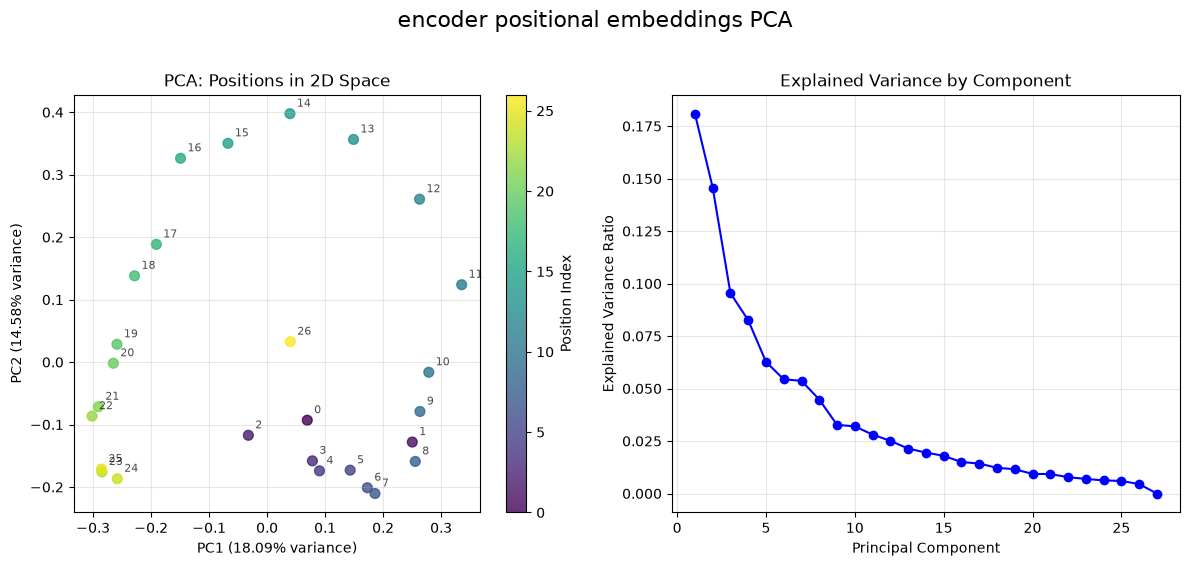

{'pos_pca_full': array([[ 6.91708252e-02, -9.30643231e-02, -2.98234671e-02,
          3.67914289e-01,  1.52019132e-03,  2.41739955e-02,
         -6.87368885e-02,  8.37013572e-02,  1.73889864e-02,
         -4.47862186e-02,  6.64660707e-02, -3.75920758e-02,
          8.32454264e-02,  6.19740747e-02, -1.10517470e-02,
          3.38822301e-03, -1.02966093e-01, -2.32238006e-02,
         -6.74854442e-02, -6.20319359e-02,  3.21705751e-02,
         -6.56307535e-03, -2.82799304e-02, -4.17913906e-02,
          5.56856170e-02,  7.32586160e-02,  4.09500956e-07],
        [ 2.50258148e-01, -1.28054395e-01,  1.49270311e-01,
          4.88117188e-01,  1.46260098e-01, -2.23957300e-01,
          9.80581641e-02, -1.26056477e-01, -7.45064244e-02,
          2.39004344e-02,  8.42781365e-03,  1.63445505e-03,
         -4.73924205e-02, -3.71900350e-02,  2.21568551e-02,
         -1.54774226e-02,  6.85010776e-02,  9.78076551e-03,
          2.97264885e-02,  2.89298780e-02, -7.31009012e-03,
          6.24634977e-0

In [12]:
analyze_positional_embeddings_pca(model, module = "encoder", n_components=28, figsize = (12,5.5), plot_labels = True)

## Ablation Studies: testing the effect of zeroing out the attention token 1s on accuracy

Analyzing the effect of zeroing out cross attention to token 1


/Users/moonshine/workspace/DyckTransformer/src/utils/transformer_analysis.py:1106: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  token_id = torch.tensor(token_id)


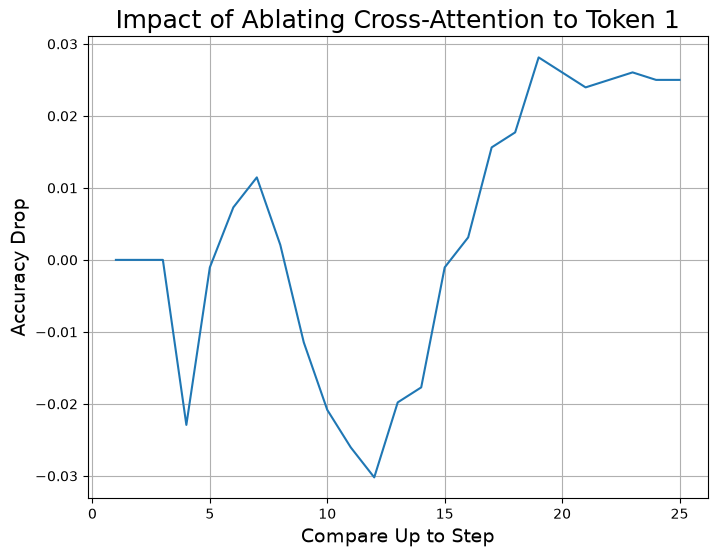

In [13]:
token_to_ablate = torch.tensor(3)  # Change this to ablate different tokens. 3 corresponds to the token for step "1" in the generated sequence.
n_batches = 30 # Number of batches to evaluate on. Each batch ahs 32 examples.
eval_steps = list(range(1,26))  # Evaluate accuracies at these generation steps

print(f"Analyzing the effect of zeroing out cross attention to token {decode([token_to_ablate], dataset.dictionary)}")
normal_accs, normal_loss = evaluator.evaluate_by_steps(max_new_tokens, eval_steps = eval_steps, n_batches=n_batches)
ablated_accuracies, ablated_avg_loss = zero_cross_attention_to_token(model, dataset, criterion, token_to_ablate, device, n_batches = n_batches, eval_steps = eval_steps)

acc_diffs = {}
for step in eval_steps:
    acc_diffs[step] = normal_accs[step] - ablated_accuracies[step]
# fix a fig size
plt.figure(figsize=(8, 6))
plt.plot(acc_diffs.keys(), acc_diffs.values(),)
plt.xlabel('Compare Up to Step', fontsize=14)
plt.ylabel('Accuracy Drop', fontsize=14)
plt.title(f'Impact of Ablating Cross-Attention to Token {decode([token_to_ablate], dataset.dictionary)}', fontsize=18)
plt.grid(True)

## Probing: how much information about levels do hidden states contain?

In [14]:
# ignore some sklearn warnings so the output is cleaner
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics._classification import UndefinedMetricWarning

# Suppress specific sklearn warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

===========Predict the level of each token based on the encoder hidden states===========
Probing Accuracy: 0.8796
===========Confusion Matrix===========


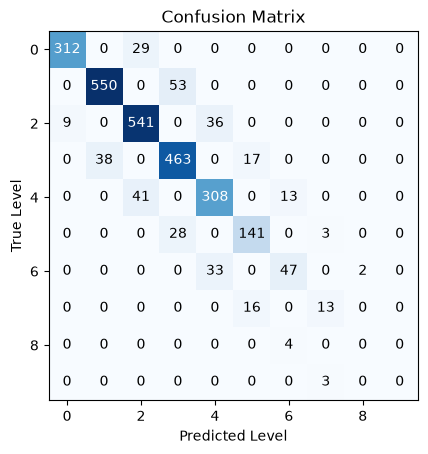

In [15]:
'''
Demonstrate probing the encoder hidden states to predict the level of each token
We extract the encoder hidden states and the level of each token in the input sequence
Then we train a simple logistic regression classifier to predict the level of each token based on the encoder hidden states
Finally, we evaluate the classifier on a held-out test set and report the accuracy

TODO: allow extracting states and levels separately
'''

# =================
# choose the number of examples for probing and the test size
n_examples = 500
test_size = 0.2
# =================

# levels = extract_levels(model, dataset.eval_dataloader, dataset.dictionary, device, max_samples=n_examples)
# states = extract_encoder_states(model, device, dataset.eval_dataloader, dataset.dictionary, max_samples=n_examples)
states, levels, positions = extract_encoder_states_and_levels(
        model, dataset.eval_dataloader, dataset.dictionary, device, max_samples=n_examples
    )
X = states.cpu().numpy()
y = levels.cpu().numpy()

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=seed)

# Train probe
probe = LogisticRegression(max_iter=1000, random_state=seed)
probe.fit(X_train, y_train)

# Evaluate
y_pred = probe.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
print("===========Predict the level of each token based on the encoder hidden states===========")
print(f"Probing Accuracy: {accuracy:.4f}")

# plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
im = plt.imshow(cm, interpolation='nearest', cmap='Blues')
print('===========Confusion Matrix===========')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Level')
plt.ylabel('True Level')

# Add text annotations
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")

## κ-specific analysis

κ does not create or destroy symbols, it only **rearranges** them: the output `N E` of $NE\cdot x$ are the root N and root E of the input,
the rest of $NE\cdot x$ is $x$, and the zip interleaves bounce segments of $NE\cdot x$ with segments of $y$.
So every output symbol has a well-defined **source position** in the input (`kappa_provenance`).
If the model implements κ as a copy/rearrangement, the decoder's cross-attention at step $t$ should point at that source position.

### κ-1. Cross-attention vs. provenance for one example
Red circles = true source position of each output symbol. Colored strip under the x-axis = region of each input position.

Input : bos 1 1 1 0 1 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 0
Target: bos 1 0 1 1 0 1 0 1 1 1 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0
regions   : NxxxxxxxxxxxxxxxxxxxxxxxxE
provenance: [0, 25, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


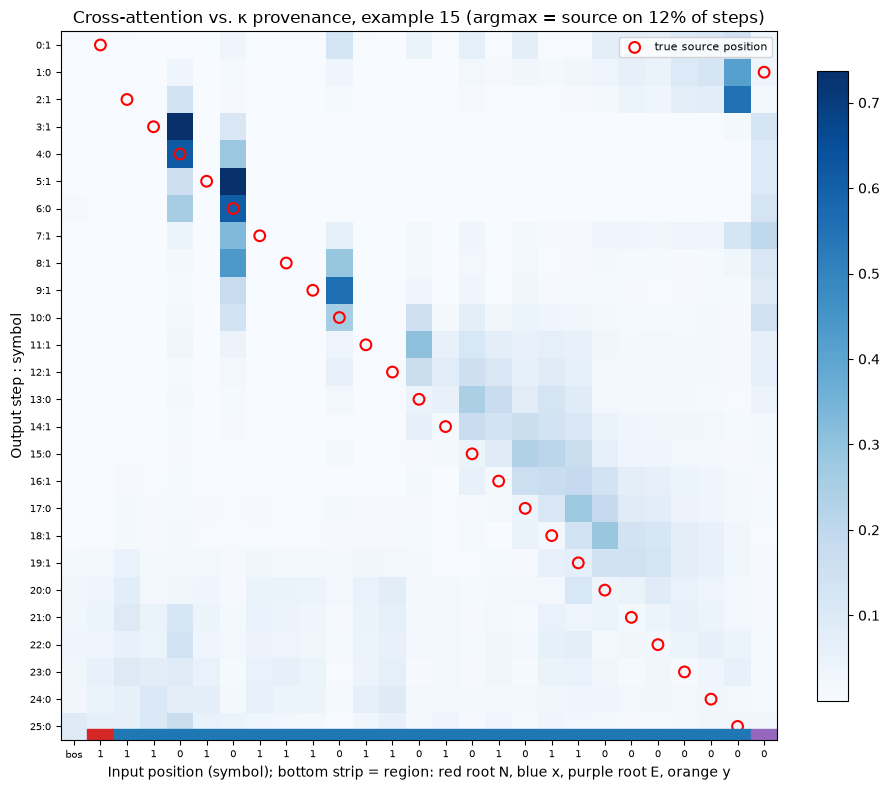

In [16]:
ex_idx = 15
print(f"Input : {decode(examples['inputs'][ex_idx], dataset.dictionary)}")
print(f"Target: {decode(examples['targets'][ex_idx], dataset.dictionary)}")
w = [int(t) - 2 for t in examples['inputs'][ex_idx][1:].tolist()]
print('regions   :', ''.join('NxEy'[r] for r in kappa_regions(w)))
print('provenance:', kappa_provenance(w))
att, prov = plot_provenance_example(model, examples, ex_idx=ex_idx, head=0)

### κ-2. Provenance alignment over many examples
How often is the most-attended input position exactly the source position (teacher-forced decoding)?

argmax(cross-attn) == source position : 0.0821
argmax within ±1 of source position   : 0.3120
mean attention weight on source       : 0.0701
top-1 by region of the source         : {'root N': 0.0, 'x': 0.0728, 'root E': 0.105, 'y': 0.0963}


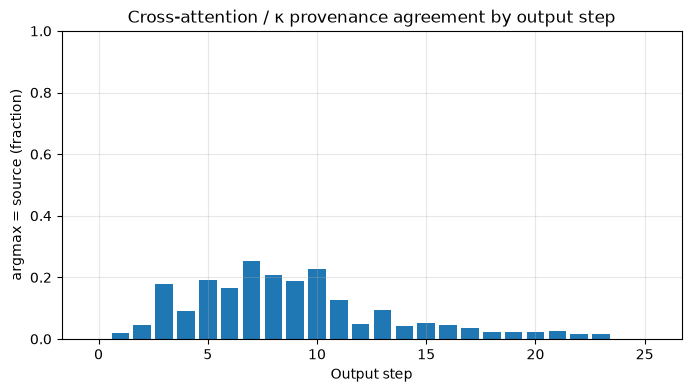

In [17]:
res = provenance_alignment(model, examples, num_examples=1000)
print(f"argmax(cross-attn) == source position : {res['top1']:.4f}")
print(f"argmax within ±1 of source position   : {res['within1']:.4f}")
print(f"mean attention weight on source       : {res['mass']:.4f}")
print("top-1 by region of the source         :", {k: round(float(v), 4) for k, v in res['top1_by_region'].items()})

plt.figure(figsize=(8, 4))
plt.bar(range(len(res['top1_by_step'])), res['top1_by_step'])
plt.xlabel('Output step'); plt.ylabel('argmax = source (fraction)')
plt.title('Cross-attention / κ provenance agreement by output step')
plt.ylim(0, 1); plt.grid(True, alpha=0.3)

### κ-3. Probing: do encoder states know the first-return decomposition?
Linear probe from each encoder hidden state to the region of its position in $w = N\,x\,E\,y$ (root N / x / root E / y).

Region probing accuracy: 0.9508


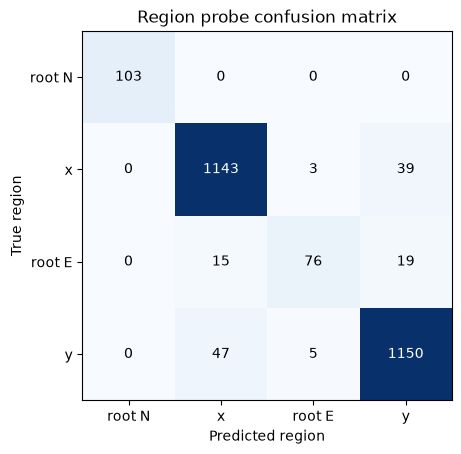

In [18]:
acc, cm, _ = probe_regions(model, examples, num_examples=500)
print(f"Region probing accuracy: {acc:.4f}")
im = plt.imshow(cm, cmap='Blues')
plt.xticks(range(4), REGION_NAMES); plt.yticks(range(4), REGION_NAMES)
plt.xlabel('Predicted region'); plt.ylabel('True region'); plt.title('Region probe confusion matrix')
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')